# Hackathon: calidad del vino
**Métodos y Modelos Matemáticos para IA · Javeriana Cali**

Este cuaderno sigue los **seis pasos de la guía oficial**, páginas 3–4. Usa solo
los modelos permitidos y los CSV entregados. Las salidas se calculan ejecutando
código; los resultados de la búsqueda completa se recuperan de archivos auditables.

La métrica oficial es **F1 macro**. No conocemos las etiquetas del test oculto.
El documento `README.md` desarrolla las decisiones en lenguaje sencillo.

**Actualización:** esta primera parte documenta la progresión base. La selección final entre las tres versiones y el CSV vigente están en la última sección.

## 1. Configuración y roles (0–10 min)
Responsabilidades propuestas: datos y fundamentos; modelos y validación; aplicación
y presentación. Los nombres y las contribuciones reales corresponden al equipo.

Cada vino es un vector de once coordenadas. `id` solo alinea la entrega y `target`
es la etiqueta binaria. Semilla 42 y los mismos cinco folds para todas las alternativas.

In [1]:
from pathlib import Path
import sys, json, io
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Ejecuta desde la raíz o notebooks/'
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from src.data import FEATURES, SEED, load_data, audit_data, validate_submission, fingerprints
from src.models import candidates, build_pipeline
from src.evaluation import evaluate_candidate, run_experiment
from src.plots import class_figure, correlation_figure, distribution_figure, pca_figure, confusion_figure
def show_fig(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=120, bbox_inches='tight')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)
train, test = load_data()
X, y = train[FEATURES], train.target.astype(int)
splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
assert 'id' not in X.columns and 'target' not in X.columns
display(pd.DataFrame({'Archivo': ['train_public.csv', 'test_public_features.csv'],
                      'Filas': [len(train), len(test)], 'Columnas': [train.shape[1], test.shape[1]]}))

,Archivo,Filas,Columnas
0,train_public.csv,5197,13
1,test_public_features.csv,1300,12


## 2. EDA y limpieza (10–30 min)
Se inspeccionan desbalance, faltantes, extremos IQR, escalas y correlaciones.
Los outliers son banderas descriptivas: no se borran por ser extremos. La imputación
por mediana queda en el pipeline para aprenderla únicamente con el entrenamiento.

train_rows                          5197
test_rows                           1300
features                              11
missing_train                          0
missing_test                           0
duplicate_feature_rows_train         807
test_rows_with_profile_in_train      337
profiles_with_conflicting_labels       1
dtype: int64

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,5197.0,7.220214,1.298977,3.90000,6.40000,7.00000,7.700,15.60000
volatile_acidity,5197.0,0.338938,0.163372,0.08000,0.23000,0.29000,0.400,1.58000
citric_acid,5197.0,0.319286,0.143941,0.00000,0.25000,0.31000,0.390,1.66000
residual_sugar,5197.0,5.473918,4.789178,0.60000,1.80000,3.10000,8.100,65.80000
chlorides,5197.0,0.055919,0.035374,0.00900,0.03800,0.04700,0.065,0.61100
free_sulfur_dioxide,5197.0,30.461228,17.559965,1.00000,17.00000,29.00000,41.000,289.00000
total_sulfur_dioxide,5197.0,116.118626,56.470374,6.00000,79.00000,118.00000,156.000,440.00000
density,5197.0,0.994706,0.003021,0.98711,0.99235,0.99489,0.997,1.03898
pH,5197.0,3.217443,0.159895,2.72000,3.11000,3.21000,3.320,4.01000
sulphates,5197.0,0.531830,0.151151,0.22000,0.43000,0.51000,0.600,2.00000


,Banderas IQR
fixed_acidity,292
volatile_acidity,294
citric_acid,397
residual_sugar,97
chlorides,224
free_sulfur_dioxide,44
total_sulfur_dioxide,6
density,3
pH,52
sulphates,161


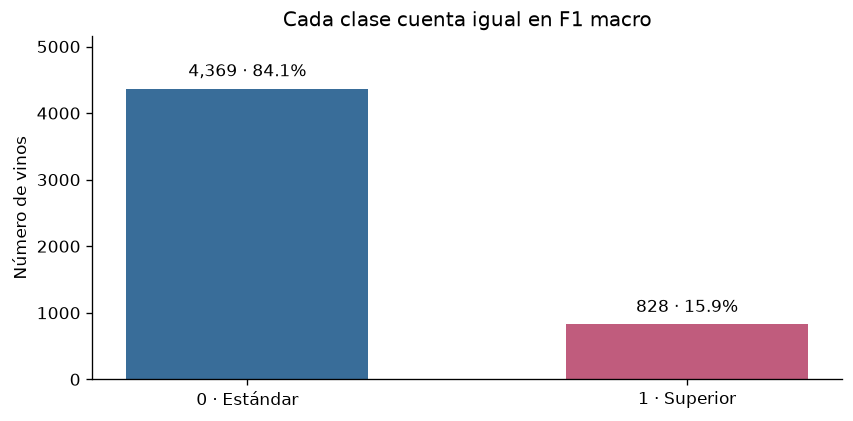

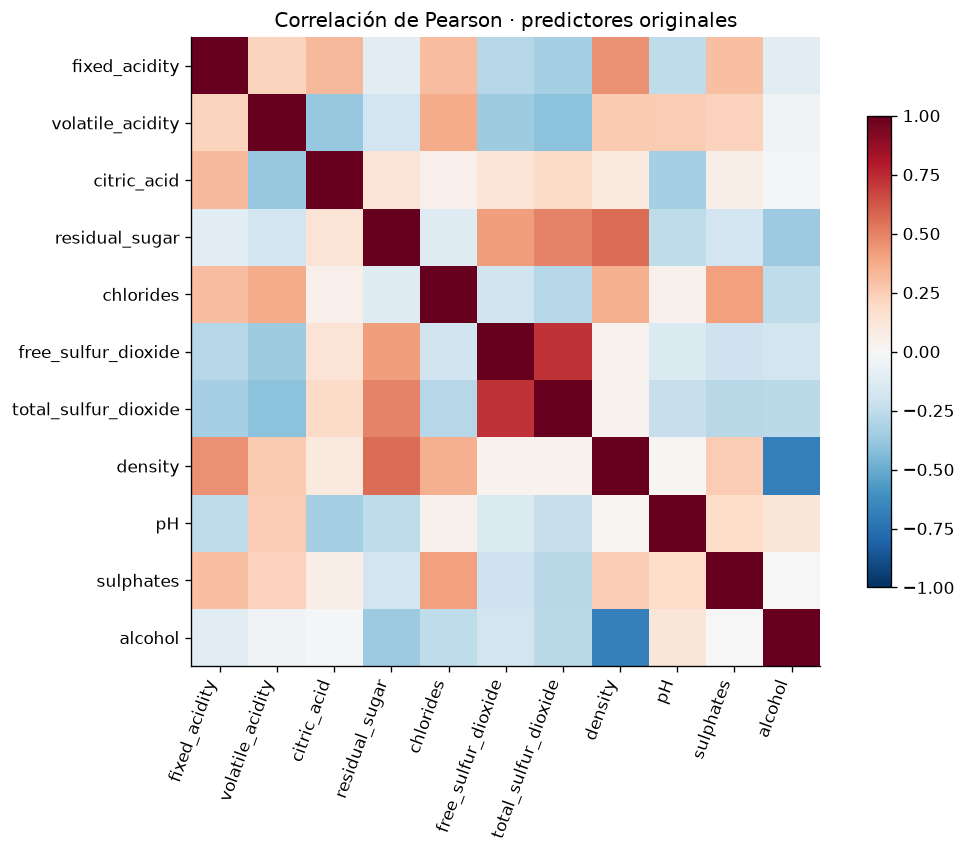

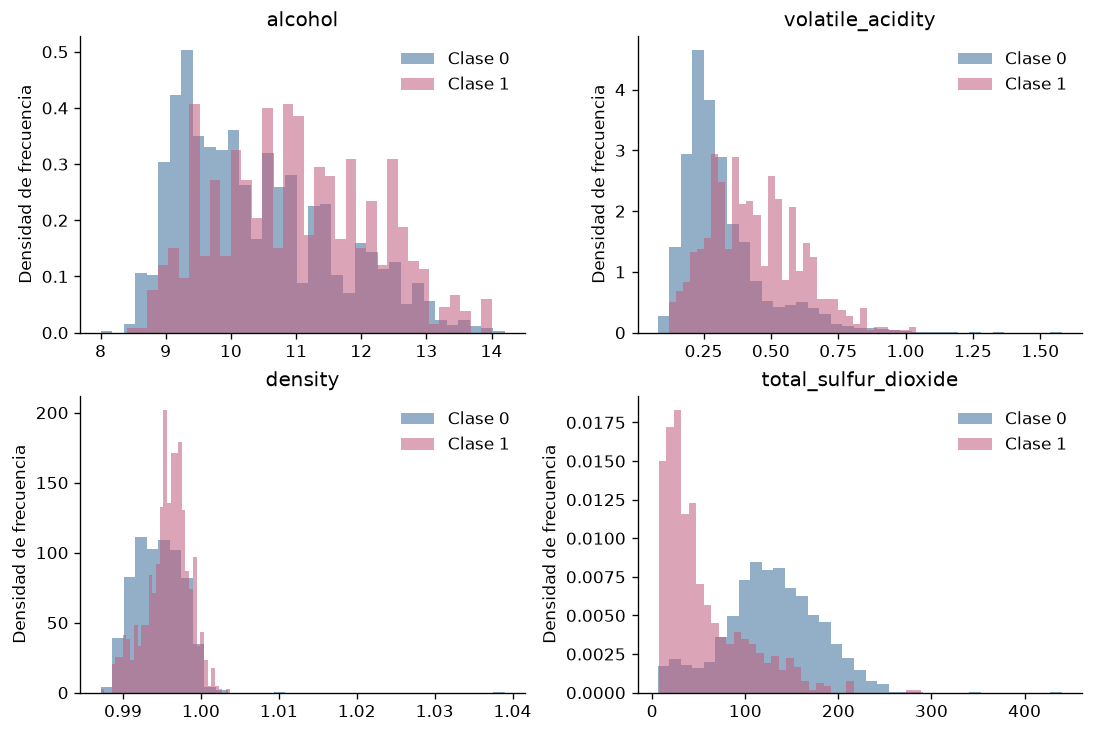

In [2]:
audit = audit_data(train, test)
display(pd.Series({k:v for k,v in audit.items() if k not in ['iqr_flags_by_feature','sha256','class_counts']}))
display(train[FEATURES].describe().T)
display(pd.DataFrame({'Banderas IQR': audit['iqr_flags_by_feature']}))
show_fig(class_figure(train))
show_fig(correlation_figure(train))
show_fig(distribution_figure(train))

In [3]:
# Por qué accuracy no basta: predecir siempre cero ignora por completo la clase superior.
all_zero = np.zeros(len(y), dtype=int)
display(pd.Series({'Accuracy siempre 0 (referencia aritmética)': accuracy_score(y, all_zero),
                   'F1 macro siempre 0 (referencia aritmética)': f1_score(y, all_zero, average='macro')}))
# No se usa un clasificador adicional fuera de los métodos permitidos.
display(Markdown(f"Hay **{audit['duplicate_feature_rows_train']} filas repetidas** por sus 11 mediciones. "
                 "Se añade una validación agrupada como control de generalización."))

Accuracy siempre 0 (referencia aritmética)    0.840677
F1 macro siempre 0 (referencia aritmética)    0.456722
dtype: float64

Hay **807 filas repetidas** por sus 11 mediciones. Se añade una validación agrupada como control de generalización.

## 3. Baseline obligatorio (30–50 min)
Se vuelve a ejecutar aquí la rejilla base completa: **k=3,5,7 × Euclidiana/Manhattan**,
más k-means con asignación por mayoría. Cada fold ajusta su propio escalador.

\(d_p(x,z)=(\sum_j |x_j-z_j|^p)^{1/p}\): Manhattan usa p=1, Euclidiana p=2.
k-NN memoriza y vota; k-means minimiza la suma de distancias cuadráticas a centroides.
La clase de un clúster se aprende solo con las etiquetas del entrenamiento del fold.

In [4]:
specs = candidates('complete')
baseline_rows = []
for spec in [s for s in specs if s.stage == 3]:
    summary, detail, oof = evaluate_candidate(spec, X, y, splits)
    baseline_rows.append(summary)
baseline_results = pd.DataFrame(baseline_rows).sort_values('f1_macro_mean', ascending=False)
display(baseline_results[['name','f1_macro_mean','f1_macro_std','f1_1_mean','fit_seconds_mean','prediction_seconds_mean']])

,name,f1_macro_mean,f1_macro_std,f1_1_mean,fit_seconds_mean,prediction_seconds_mean
1,base_knn_k3_manhattan,0.806608,0.018421,0.673098,0.006413,0.036452
0,base_knn_k3_euclidean,0.803445,0.016307,0.667805,0.011278,0.018162
4,base_knn_k7_euclidean,0.800782,0.005737,0.660921,0.005091,0.014999
2,base_knn_k5_euclidean,0.799769,0.013065,0.660342,0.005364,0.015062
3,base_knn_k5_manhattan,0.798709,0.020042,0.658288,0.005018,0.035594
5,base_knn_k7_manhattan,0.798494,0.017233,0.657980,0.005232,0.035809
6,base_kmeans_2,0.766521,0.014649,0.628810,0.020430,0.001898
7,base_kmeans_16,0.748131,0.032904,0.564575,0.115296,0.001854


## 4. Variables nuevas y PCA (50–75 min)
Se conservan los once atributos y se agregan tres cocientes antes del escalado:

1. Acidez fija / volátil: balance relativo entre formas de acidez.
2. SO₂ libre / total: fracción del dióxido de azufre que está libre.
3. Alcohol / densidad: relación empírica entre dos propiedades relacionadas.

Son hipótesis de representación, no relaciones causales demostradas. Denominadores
casi nulos generan NaN y se imputan dentro del fold. También se ensayan distancias
a ocho centroides aprendidos únicamente con el entrenamiento.

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,fixed_volatile_ratio,free_total_so2_ratio,alcohol_density_ratio
0,6.8,0.33,0.30,2.1,0.047,35.0,147.0,0.98860,3.24,0.56,13.400000,20.606061,0.238095,13.554522
1,5.3,0.47,0.11,2.2,0.048,16.0,89.0,0.99182,3.54,0.88,13.566667,11.276596,0.179775,13.678557
2,6.6,0.36,0.28,6.1,0.029,12.0,93.0,0.99054,3.19,0.27,12.800000,18.333333,0.129032,12.922244
3,6.8,0.43,0.30,3.5,0.033,27.0,135.0,0.99060,3.00,0.37,12.000000,15.813953,0.200000,12.113870
4,6.5,0.24,0.38,1.0,0.027,31.0,90.0,0.98926,3.24,0.36,12.300000,27.083333,0.344444,12.433536


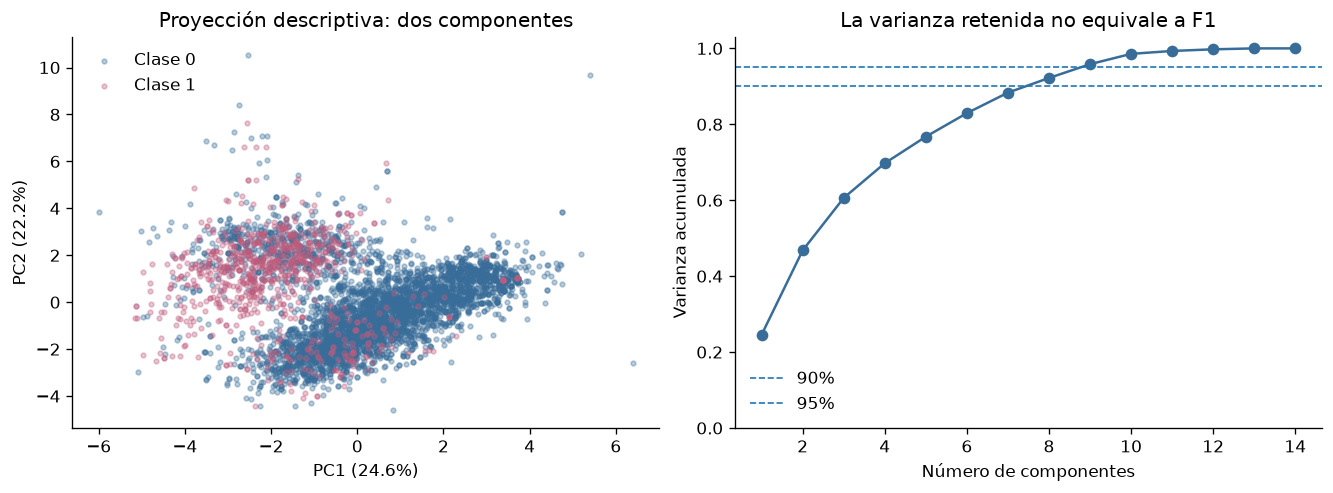

In [5]:
from src.features import ChemicalRatios, RATIO_NAMES
ratios = ChemicalRatios().fit_transform(X)
display(pd.DataFrame(ratios[:5], columns=FEATURES + RATIO_NAMES))
assert ratios.shape[1] == 14
show_fig(pca_figure(train))

### Conexión con el ejemplo de PCA de clase
Se reproduce el conjunto de cuatro estudiantes de `PCA_TeoríaConEjemplo.html`.
La clase divide covarianza por N; scikit-learn informa varianzas con N−1.
Ese factor común cambia autovalores, pero conserva direcciones y porcentajes.
Los signos de los autovectores pueden invertirse sin cambiar el subespacio.

In [6]:
toy = np.array([[1,3],[2,2],[4,6],[5,5]], dtype=float)
centered = toy - toy.mean(axis=0)
covariance = centered.T @ centered / len(toy)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
display(pd.DataFrame(covariance))
display(pd.DataFrame({'autovalor': eigenvalues, 'fracción de varianza': eigenvalues/eigenvalues.sum()}))
display(pd.DataFrame(centered @ eigenvectors[:, :1], columns=['PC1']))
np.testing.assert_allclose(eigenvalues, [4.5, 0.5])

,0,1
0,2.5,2.0
1,2.0,2.5


,autovalor,fracción de varianza
0,4.5,0.9
1,0.5,0.1


,PC1
0,-2.12132
1,-2.12132
2,2.12132
3,2.12132


In [7]:
# Ablación controlada: k=5 y Manhattan permanecen fijos.
ablation_rows = [next(row for row in baseline_rows if row['name'] == 'base_knn_k5_manhattan')]
for spec in [s for s in specs if s.name in ['fe_knn_k5_manhattan',
             'pca0.9_knn_k5_manhattan', 'pca0.95_knn_k5_manhattan']]:
    summary, _, _ = evaluate_candidate(spec, X, y, splits)
    ablation_rows.append(summary)
ablation = pd.DataFrame(ablation_rows)
display(ablation[['name','f1_macro_mean','f1_macro_std','dimensions_mean','fit_seconds_mean','prediction_seconds_mean']])
display(Markdown('PCA se decide por su resultado y tiempo medidos; retener varianza no garantiza conservar la separación entre clases.'))

,name,f1_macro_mean,f1_macro_std,dimensions_mean,fit_seconds_mean,prediction_seconds_mean
0,base_knn_k5_manhattan,0.798709,0.020042,11.0,0.005018,0.035594
1,fe_knn_k5_manhattan,0.797471,0.014686,14.0,0.005219,0.039034
2,pca0.9_knn_k5_manhattan,0.799745,0.018188,8.0,0.006556,0.030819
3,pca0.95_knn_k5_manhattan,0.799336,0.008884,9.0,0.006269,0.032615


PCA se decide por su resultado y tiempo medidos; retener varianza no garantiza conservar la separación entre clases.

## 5. SVM y MLP (75–100 min)
**SVM:** se comparan kernels lineal, polinomial y RBF; C regula la penalización por
violaciones y gamma el alcance de RBF. Se compara `class_weight=None/balanced`.

**MLP:** una o dos capas, ReLU/tanh y alpha. La red minimiza entropía cruzada
regularizada mediante Adam; backpropagation calcula gradientes. No minimiza F1
directamente. Se prueba ponderación de clases calculada solo dentro del fold.

El registro `src/models.py` contiene toda la rejilla explícita. No se utilizan árboles,
boosting ni AutoML. Para repetir los 79 candidatos cambia `REENTRENAR_TODO=True`.
Si faltan los resultados completos, se generan automáticamente.

In [8]:
REENTRENAR_TODO = False
if REENTRENAR_TODO or not (ROOT/'outputs/experiment.json').exists():
    results, metadata = run_experiment('complete')
else:
    results = pd.read_csv(ROOT/'outputs/cv_results.csv')
    metadata = json.loads((ROOT/'outputs/experiment.json').read_text(encoding='utf-8'))
assert metadata['sha256'] == fingerprints(), 'Los resultados pertenecen a otros datos'
assert metadata['profile'] == 'complete' and metadata['folds'] == 5
display(results[['name','family','f1_macro_mean','f1_macro_std','f1_1_mean','fit_seconds_mean']])

,name,family,f1_macro_mean,f1_macro_std,f1_1_mean,fit_seconds_mean
0,fe_knn_k11_cosine_distance,k-NN,0.850976,0.017459,0.747769,0.006791
1,fe_knn_k7_minkowski_distance,k-NN,0.847711,0.011057,0.741989,0.006261
2,fe_knn_k7_manhattan_distance,k-NN,0.847173,0.016702,0.741154,0.006319
3,fe_knn_k11_euclidean_distance,k-NN,0.846491,0.016307,0.739332,0.006300
4,centroids8_knn,k-NN,0.845622,0.018371,0.739200,0.098921
...,...,...,...,...,...,...
74,svm_rbf_C1_gscale_wbalanced,SVM,0.780610,0.016086,0.648106,0.303332
75,svm_poly_C100_gscale_wbalanced,SVM,0.780265,0.012687,0.647048,2.969053
76,svm_poly_C1_gscale_wNone,SVM,0.773765,0.021176,0.605334,0.210799
77,base_kmeans_2,k-means,0.766521,0.014649,0.628810,0.020793


In [9]:
# Reejecución representativa: mejor SVM de cada kernel y mejor MLP.
selected_names = []
for kernel in ['linear', 'poly', 'rbf']:
    names = [s.name for s in specs if s.family == 'SVM' and s.params['kernel'] == kernel]
    selected_names.append(results[results.name.isin(names)].iloc[0]['name'])
selected_names.append(results[results.family == 'MLP'].iloc[0]['name'])
advanced_check = []
for name in selected_names:
    spec = next(s for s in specs if s.name == name)
    summary, _, _ = evaluate_candidate(spec, X, y, splits)
    expected = float(results.loc[results.name == name, 'f1_macro_mean'].iloc[0])
    np.testing.assert_allclose(summary['f1_macro_mean'], expected, atol=1e-12)
    advanced_check.append(summary)
display(pd.DataFrame(advanced_check)[['name','f1_macro_mean','f1_macro_std','f1_1_mean','warnings_count']])

,name,f1_macro_mean,f1_macro_std,f1_1_mean,warnings_count
0,svm_linear_C0.1_gscale_wNone,0.808909,0.015906,0.673194,0
1,svm_poly_C10_gscale_wNone,0.792285,0.008969,0.641424,0
2,svm_rbf_C10_g0.03_wNone,0.813757,0.011012,0.679648,0
3,mlp_64_32_relu_a0.01_bTrue,0.823523,0.026355,0.707552,5


## 6. Selección, Streamlit, submission y pitch (100–120 min)
Se elige el mayor F1 macro medio de los mismos cinco folds. En empate se compara
menor desviación y nombre. El ganador puede ser un método sencillo: avanzar hacia
modelos más complejos significa evaluarlos, no asumir que ganan.

La CV se utiliza para seleccionar hiperparámetros; su máximo puede ser optimista.
La desviación entre folds no es un intervalo de confianza. El control por perfiles
también es diagnóstico del ganador ya elegido, no una evaluación anidada.

name                                fe_knn_k11_cosine_distance
stage                                                        4
family                                                    k-NN
params       {'n_neighbors': 11, 'metric': 'cosine', 'weigh...
ratios                                                    True
pca                                                       None
centroids                                                 None
dtype: object

F1 macro CV                      0.850976
Desviación entre folds           0.017459
F1 macro control por perfiles    0.804143
F1 test oculto                        NaN
dtype: float64

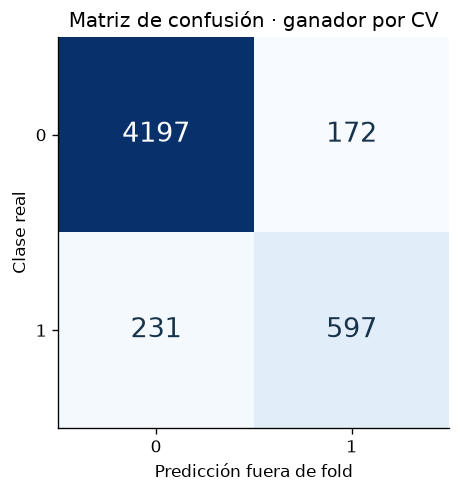

,name,fold,stage,family,f1_macro,f1_0,f1_1,precision_1,recall_1,accuracy,fit_seconds,prediction_seconds,input_dimensions,warnings_count,warnings
0,fe_knn_k11_cosine_distance,1,4,k-NN,0.792622,0.941176,0.644068,0.736434,0.572289,0.899038,0.007390,0.084166,14,0,NaN
1,fe_knn_k11_cosine_distance,2,4,k-NN,0.821725,0.944064,0.699387,0.708075,0.690909,0.905679,0.004972,0.074944,14,0,NaN
2,fe_knn_k11_cosine_distance,3,4,k-NN,0.811608,0.945475,0.677741,0.755556,0.614458,0.906731,0.004921,0.073011,14,0,NaN
3,fe_knn_k11_cosine_distance,4,4,k-NN,0.797871,0.937358,0.658385,0.679487,0.638554,0.894129,0.004980,0.092120,14,0,NaN
4,fe_knn_k11_cosine_distance,5,4,k-NN,0.796888,0.940181,0.653595,0.709220,0.606061,0.897979,0.011726,0.083113,14,0,NaN


In [10]:
display(pd.Series(metadata['best']))
display(pd.Series({'F1 macro CV': metadata['best_cv']['f1_macro_mean'],
                   'Desviación entre folds': metadata['best_cv']['f1_macro_std'],
                   'F1 macro control por perfiles': metadata['grouped_diagnostic']['f1_macro_mean'],
                   'F1 test oculto': metadata['hidden_test_f1_macro']}))
show_fig(confusion_figure(metadata['oof_confusion_matrix']))
display(pd.read_csv(ROOT/'outputs/grouped_validation_folds.csv'))

In [11]:
# Reproducir y verificar la entrega usando el modelo final ajustado con TODO train.
import joblib
artifact = joblib.load(ROOT/'outputs'/metadata['artifacts'][metadata['best']['name']])
with threadpool_limits(limits=1):
    prediction = artifact['pipeline'].predict(test[FEATURES]).astype(int)
submission = pd.DataFrame({'id': test.id, 'prediction': prediction})
assert validate_submission(submission, test)
saved = pd.read_csv(ROOT/'outputs/submission_base.csv')
pd.testing.assert_frame_equal(saved, submission)
assert len(saved) == 1300 and list(saved.columns) == ['id', 'prediction']
display(saved.head(10))
display(saved.prediction.value_counts().rename('Cantidad de predicciones'))
print('Verificado: 1.300 observaciones + cabecera = 1.301 líneas; orden de id conservado.')

,id,prediction
0,WINE_5797,0
1,WINE_3083,0
2,WINE_3591,0
3,WINE_4648,0
4,WINE_5334,0
5,WINE_1389,0
6,WINE_3150,0
7,WINE_6343,0
8,WINE_1381,0
9,WINE_6067,0


prediction
0    1112
1     188
Name: Cantidad de predicciones, dtype: int64

Verificado: 1.300 observaciones + cabecera = 1.301 líneas; orden de id conservado.


### Aplicación y entregables
Abrir `app/app.py` con Streamlit. La app contiene mejor modelo, comparativa de tres
versiones, simulador modular, EDA/PCA y recorrido técnico por los seis pasos.
README.md documenta ejecución, resultados y parámetros; la última sección de este
cuaderno comprueba el CSV de la selección consolidada.

## Selección final entre tres proyectos

Se reutilizan las 116 métricas existentes (79 + 22 + 15), sin nuevas búsquedas. Se
comparan decisiones estándar y se separa el ajuste de umbral. El ganador es k-NN
k=23 con coseno, votos por distancia y centroides 2/6. No utiliza PCA. Los resultados
anteriores del cuaderno son históricos del proyecto base; el CSV vigente se verifica aquí.

In [12]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT/'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import joblib
from IPython.display import display
from src.data import load_data, FEATURES, validate_submission
train, test = load_data()
final = json.loads((ROOT/'outputs/consolidated.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(ROOT/'outputs/project_comparison.csv')
display(comparison[['source','name','f1_macro','reported_f1','adjusted_threshold']].head(15))
winner = next(m for m in final['models'] if m['id'] == final['winner_id'])
display(pd.Series({'Modelo': winner['name'], 'F1 macro estándar': winner['f1_macro'], 'Parámetros': winner['params']}))
pipe = joblib.load(ROOT/'outputs'/winner['artifact'])['pipeline']
submission = pd.read_csv(ROOT/'entregas/submission.csv')
assert validate_submission(submission, test)
np.testing.assert_array_equal(pipe.predict(test[FEATURES]), submission.prediction)
display(submission.head())
print('Entrega final comprobada: 1.300 predicciones del ganador consolidado. Sin reentrenar.')

,source,name,f1_macro,reported_f1,adjusted_threshold
0,Versión Alejo,"FE + Distancias k-Means + k-NN (k=23, Coseno)",0.862372,0.862372,False
1,Versión Alejo,FE + PCA (90% var) + k-NN (Coseno),0.860466,0.860958,True
2,Versión Alejo,FE + PCA (95% var) + k-NN (Coseno),0.859733,0.861302,True
3,Versión Alejo,"FE Fisicoquímico + k-NN Hipersférico (k=19, Co...",0.859451,0.861878,True
4,Versión Alejo,"k-NN (k=15, Coseno, 1/d)",0.851716,0.858664,True
5,Versión Alejo,"k-NN (k=7, Minkowski p=1.5, 1/d)",0.851173,0.851173,False
6,Proyecto base,fe_knn_k11_cosine_distance,0.850976,0.850976,False
7,Versión alternativa,k-NN L1 k=31 ponderado + ratios,0.849037,0.849037,False
8,Proyecto base,fe_knn_k7_minkowski_distance,0.847711,0.847711,False
9,Proyecto base,fe_knn_k7_manhattan_distance,0.847173,0.847173,False


Modelo                                      k-NN · coseno + centroides
F1 macro estándar                                             0.862372
Parámetros           {'n_neighbors': 23, 'metric': 'cosine', 'weigh...
dtype: object

,id,prediction
0,WINE_5797,0
1,WINE_3083,0
2,WINE_3591,0
3,WINE_4648,0
4,WINE_5334,0


Entrega final comprobada: 1.300 predicciones del ganador consolidado. Sin reentrenar.
